# DATA 266 - Homework 7
## GAN theory and FashionMNIST autoencoders

**Student:** Nikhil Kanaparthi  
**SID4:** 6441  
**Framework:** PyTorch  
**Models:** Fully Connected Autoencoder (FC-AE) and Variational Autoencoder (VAE)

### How to run this notebook

1. In Colab, choose **Runtime > Change runtime type > GPU**.
2. Run each cell from top to bottom.
3. Keep `FAST_DEV_RUN = False` for the final submission.
4. At the end, download the generated ZIP and also download this executed notebook.

The two models use the same FashionMNIST train/validation/test data, batch size, latent dimension, and epoch budget. Common reconstruction metrics are calculated on the same test set so the comparison is fair.


## Question 1A - Fundamental GAN architecture

A Generative Adversarial Network contains two neural networks with opposing objectives. The **generator** $G$ receives a random latent vector $z \sim p_z$ and transforms it into a synthetic sample $G(z)$. Its goal is to produce samples that resemble examples from the real data distribution. The **discriminator** $D$ receives either a real sample $x$ or a generated sample $G(z)$ and estimates whether the input came from the real dataset.

Training alternates between the two networks. During the discriminator step, $G$ is held fixed while $D$ learns to assign high scores to real samples and low scores to generated samples. During the generator step, $D$ is held fixed while gradients are propagated through $D(G(z))$ into $G$. The generator therefore learns changes that make its samples more likely to be classified as real. A common practical generator objective is the non-saturating loss $-\mathbb{E}_z[\log D(G(z))]$ because it provides stronger gradients early in training.

The original minimax game is

$$
\min_G \max_D V(D,G)
= \mathbb{E}_{x \sim p_{data}}[\log D(x)]
+ \mathbb{E}_{z \sim p_z}[\log(1-D(G(z)))].
$$

For a fixed generator, the optimal discriminator is $D^*(x)=\frac{p_{data}(x)}{p_{data}(x)+p_g(x)}$. In the idealized global equilibrium, the generator distribution matches the data distribution, $p_g=p_{data}$, and the discriminator cannot distinguish them, so $D(x)=0.5$. In practice, the networks are optimized with finite data and alternating gradient updates, so training may oscillate or become unstable instead of reaching this exact equilibrium.


## Question 1B - Mode collapse and mitigation

**Mode collapse** occurs when many different latent inputs are mapped to the same output or to a small collection of outputs. The generated images may look plausible, but they cover only a few modes of the real distribution. It can occur because the generator discovers a limited set of samples that currently fool the discriminator and receives no immediate reward for representing missing modes. The discriminator then adapts, the generator moves to another narrow solution, and the adversarial dynamics can cycle.

Three useful mitigation approaches are:

1. **Minibatch discrimination.** The discriminator is given features that compare each example with other examples in the same minibatch. A batch containing many nearly identical generated samples is therefore easier to reject. Because the discriminator evaluates diversity across samples instead of judging every image independently, the generator receives a direct gradient signal encouraging varied outputs.

2. **Wasserstein loss with gradient penalty (WGAN-GP).** A critic estimates a smooth Wasserstein-distance objective rather than a saturated binary classification objective. The gradient penalty encourages the critic to remain approximately 1-Lipschitz along lines between real and generated samples. This produces more informative, stable gradients even when the real and generated distributions have little overlap, reducing the incentive to jump between a few modes.

3. **Unrolled GAN training.** When updating the generator, the optimization differentiates through several simulated future discriminator updates. The generator can therefore anticipate that a temporarily successful collapsed output will soon be rejected. This discourages short-term exploitation of discriminator weaknesses and promotes broader coverage.

These techniques address different causes of collapse: minibatch discrimination exposes low diversity, WGAN-GP improves gradient quality, and unrolling reduces myopic generator updates.


## Question 1C - Three important GAN variants

| Variant | Limitation addressed | Main innovation |
|---|---|---|
| **DCGAN** | Early fully connected GANs were difficult to scale to images and often produced weak spatial structure. | Replaces dense image-processing layers with convolutional and transposed-convolutional layers, uses batch normalization, removes most pooling layers, and applies architecture guidelines such as ReLU in the generator and LeakyReLU in the discriminator. These choices provide a stronger image-specific inductive bias and more stable optimization. |
| **Conditional GAN (cGAN)** | A standard GAN gives the user little control over which class or attribute is generated. | Supplies side information $y$—such as a class label—to both $G$ and $D$. The generator models $G(z,y)$ and the discriminator evaluates whether an image is both realistic and compatible with $y$. Conditioning enables targeted generation and class-specific sampling. |
| **CycleGAN** | Paired examples are often unavailable for image-to-image translation tasks such as horses-to-zebras or photos-to-paintings. | Learns two generators, $G:X\rightarrow Y$ and $F:Y\rightarrow X$, plus one discriminator for each domain. Adversarial losses make translated images resemble the target domain, while cycle-consistency losses require $F(G(x))\approx x$ and $G(F(y))\approx y$. This makes translation possible from unpaired datasets. An identity loss can additionally discourage unnecessary color or content changes. |

DCGAN mainly improves convolutional image generation, cGAN introduces explicit control, and CycleGAN addresses unpaired cross-domain translation. They solve different limitations rather than being interchangeable replacements.


## References

1. Goodfellow, I. et al. (2014). *Generative Adversarial Nets*. NeurIPS.
2. Radford, A., Metz, L., & Chintala, S. (2016). *Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks*. ICLR.
3. Mirza, M., & Osindero, S. (2014). *Conditional Generative Adversarial Nets*. arXiv:1411.1784.
4. Zhu, J.-Y. et al. (2017). *Unpaired Image-to-Image Translation Using Cycle-Consistent Adversarial Networks*. ICCV.
5. Salimans, T. et al. (2016). *Improved Techniques for Training GANs*. NeurIPS.
6. Gulrajani, I. et al. (2017). *Improved Training of Wasserstein GANs*. NeurIPS.


# Question 2 - FashionMNIST FC-AE and VAE

The experiment below trains both models from scratch. FashionMNIST labels are not used for optimization because reconstruction is unsupervised; labels are retained only for per-class error analysis.


In [15]:
# Imports, student-specific parameters, and reproducibility
from pathlib import Path
from datetime import datetime, timezone
import json
import math
import os
import platform
import random
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from tqdm.auto import tqdm

STUDENT = "Nikhil Kanaparthi"
SID4 = 6441
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 7
CLS_A = SID4 % 10
CLS_B = (SID4 // 10) % 10

# Keep False for the submitted run. True is only a short code check.
FAST_DEV_RUN = False

LATENT_DIM = 32
BATCH_SIZE = 512
EPOCHS_FC = 15 if not FAST_DEV_RUN else 2
EPOCHS_VAE = 15 if not FAST_DEV_RUN else 2
LEARNING_RATE = 1e-3
BETA = 1.0
NUM_WORKERS = 0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = Path("/content/HW7_FashionMNIST_Nikhil_Kanaparthi_6441")
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
for directory in [OUTPUT_DIR, FIGURE_DIR, MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()

RUN_LOG_LINES = []
def log(message):
    line = f"[{datetime.now(timezone.utc).isoformat()}] {message}"
    RUN_LOG_LINES.append(line)
    print(line)

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
log(f"Student={STUDENT} SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID}")
log(f"Python={platform.python_version()} Torch={torch.__version__} Torchvision={torchvision.__version__}")
log(f"Device={DEVICE} Hardware={gpu_name} FAST_DEV_RUN={FAST_DEV_RUN}")
print("Output directory:", OUTPUT_DIR)


[2026-10-20T06:52:37.779537+00:00] Student=Nikhil Kanaparthi SID4=6441 SEED=6441 SLICE=441 HP_ID=1
[2026-10-20T06:52:37.779699+00:00] Python=3.13.15 Torch=2.11.0+cu130 Torchvision=0.26.0+cu130
[2026-10-20T06:52:37.779800+00:00] Device=cuda Hardware=Tesla T4 FAST_DEV_RUN=False
Output directory: /content/HW7_FashionMNIST_Nikhil_Kanaparthi_6441


## Load and inspect FashionMNIST

The official 60,000-image training set is split deterministically into 54,000 training images and 6,000 validation images. The official 10,000-image test set is used once for final evaluation. Pixel values are scaled to $[0,1]$ and flattened to 784 values for the fully connected networks.


In [16]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda image: image.flatten()),
])

data_root = "/content/fashion_mnist_data"
full_train_dataset = datasets.FashionMNIST(
    root=data_root, train=True, download=True, transform=transform
)
test_dataset = datasets.FashionMNIST(
    root=data_root, train=False, download=True, transform=transform
)

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    [54_000, 6_000],
    generator=torch.Generator().manual_seed(SEED),
)

if FAST_DEV_RUN:
    rng = np.random.default_rng(SEED)
    train_dataset = Subset(train_dataset, rng.choice(len(train_dataset), 8_000, replace=False).tolist())
    validation_dataset = Subset(validation_dataset, rng.choice(len(validation_dataset), 1_000, replace=False).tolist())
    test_dataset = Subset(test_dataset, rng.choice(len(test_dataset), 2_000, replace=False).tolist())

loader_generator = torch.Generator().manual_seed(SEED)
loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
}

train_loader = DataLoader(
    train_dataset, shuffle=True, generator=loader_generator, **loader_kwargs
)
validation_loader = DataLoader(validation_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

sample_x, sample_y = next(iter(train_loader))
assert sample_x.shape[1] == 784
assert float(sample_x.min()) >= 0.0 and float(sample_x.max()) <= 1.0

log(
    f"Dataset sizes train={len(train_dataset)} validation={len(validation_dataset)} "
    f"test={len(test_dataset)} batch_size={BATCH_SIZE}"
)
print("Batch image shape:", sample_x.shape)
print("Batch label shape:", sample_y.shape)
print("Pixel range:", float(sample_x.min()), "to", float(sample_x.max()))


[2026-10-20T06:52:37.941945+00:00] Dataset sizes train=54000 validation=6000 test=10000 batch_size=512
Batch image shape: torch.Size([512, 784])
Batch label shape: torch.Size([512])
Pixel range: 0.0 to 1.0


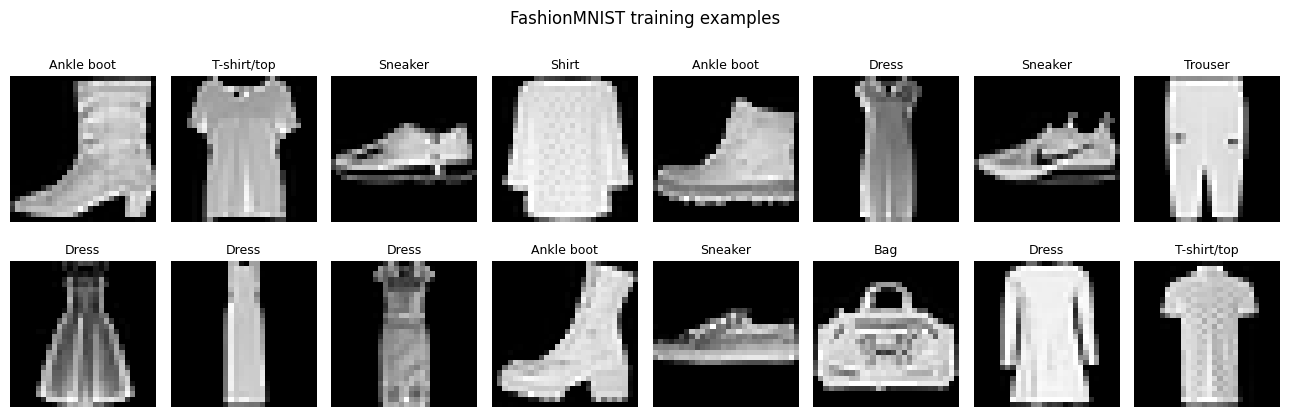

In [17]:
# Display examples from the actual training data
fig, axes = plt.subplots(2, 8, figsize=(13, 4.5))
for index, axis in enumerate(axes.flat):
    axis.imshow(sample_x[index].reshape(28, 28), cmap="gray")
    axis.set_title(CLASS_NAMES[int(sample_y[index])], fontsize=9)
    axis.axis("off")
fig.suptitle("FashionMNIST training examples")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fashionmnist_examples.png", dpi=180, bbox_inches="tight")
plt.show()


## Model 1 - Fully Connected Autoencoder (FC-AE)

The FC-AE is deterministic. Its encoder compresses a 784-dimensional image into a 32-dimensional latent vector; the decoder reconstructs the image. Binary cross-entropy is appropriate because each normalized pixel lies in $[0,1]$ and the decoder ends with a sigmoid.


In [18]:
class FullyConnectedAutoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters())


fc_ae = FullyConnectedAutoencoder().to(DEVICE)
print(fc_ae)
print(f"FC-AE parameters: {parameter_count(fc_ae):,}")
assert fc_ae(sample_x[:2].to(DEVICE)).shape == (2, 784)


FullyConnectedAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)
FC-AE parameters: 439,728


In [19]:
def train_fc_autoencoder(model, train_loader, validation_loader, epochs):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history = []

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        model.train()
        train_bce_sum = 0.0
        train_pixels = 0

        progress = tqdm(train_loader, desc=f"FC-AE epoch {epoch}/{epochs}")
        for images, _ in progress:
            images = images.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            reconstruction = model(images)
            loss = F.binary_cross_entropy(reconstruction, images, reduction="mean")
            loss.backward()
            optimizer.step()

            train_bce_sum += F.binary_cross_entropy(
                reconstruction.detach(), images, reduction="sum"
            ).item()
            train_pixels += images.numel()
            progress.set_postfix(bce_per_pixel=f"{train_bce_sum/train_pixels:.5f}")

        model.eval()
        validation_bce_sum = 0.0
        validation_pixels = 0
        with torch.inference_mode():
            for images, _ in validation_loader:
                images = images.to(DEVICE, non_blocking=True)
                reconstruction = model(images)
                validation_bce_sum += F.binary_cross_entropy(
                    reconstruction, images, reduction="sum"
                ).item()
                validation_pixels += images.numel()

        row = {
            "model": "FC-AE",
            "epoch": epoch,
            "train_loss": train_bce_sum / train_pixels,
            "validation_loss": validation_bce_sum / validation_pixels,
            "train_reconstruction": train_bce_sum / train_pixels,
            "validation_reconstruction": validation_bce_sum / validation_pixels,
            "train_kl": np.nan,
            "validation_kl": np.nan,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "seconds": time.perf_counter() - start,
        }
        history.append(row)
        log(json.dumps(row, sort_keys=True, allow_nan=True))
        scheduler.step()

    return history


fc_history = train_fc_autoencoder(fc_ae, train_loader, validation_loader, EPOCHS_FC)
torch.save(fc_ae.state_dict(), MODEL_DIR / "fc_autoencoder_state_dict.pt")
print("FC-AE training complete and model saved.")


FC-AE epoch 1/15:   0%|          | 0/106 [00:00<?, ?it/s]

[2026-10-20T06:52:46.592062+00:00] {"epoch": 1, "learning_rate": 0.001, "model": "FC-AE", "seconds": 7.527662386999964, "train_kl": NaN, "train_loss": 0.44080889094461567, "train_reconstruction": 0.44080889094461567, "validation_kl": NaN, "validation_loss": 0.3514188008211097, "validation_reconstruction": 0.3514188008211097}


FC-AE epoch 2/15:   0%|          | 0/106 [00:00<?, ?it/s]

[2026-10-20T06:52:54.290380+00:00] {"epoch": 2, "learning_rate": 0.0009890738003669028, "model": "FC-AE", "seconds": 7.698099492999972, "train_kl": NaN, "train_loss": 0.33533162453349397, "train_reconstruction": 0.33533162453349397, "validation_kl": NaN, "validation_loss": 0.3249516119924532, "validation_reconstruction": 0.3249516119924532}


FC-AE epoch 3/15:   0%|          | 0/106 [00:00<?, ?it/s]

...

[2026-10-20T06:54:18.131034+00:00] {"epoch": 13, "learning_rate": 9.549150281252631e-05, "model": "FC-AE", "seconds": 7.731833118000054, "train_kl": NaN, "train_loss": 0.29419342691503686, "train_reconstruction": 0.29419342691503686, "validation_kl": NaN, "validation_loss": 0.29471155864689624, "validation_reconstruction": 0.29471155864689624}


FC-AE epoch 14/15:   0%|          | 0/106 [00:00<?, ?it/s]

[2026-10-20T06:54:25.933888+00:00] {"epoch": 14, "learning_rate": 4.322727117869951e-05, "model": "FC-AE", "seconds": 7.80263651000007, "train_kl": NaN, "train_loss": 0.2939819775132275, "train_reconstruction": 0.2939819775132275, "validation_kl": NaN, "validation_loss": 0.2945504391209609, "validation_reconstruction": 0.2945504391209609}


FC-AE epoch 15/15:   0%|          | 0/106 [00:00<?, ?it/s]

[2026-10-20T06:54:33.825570+00:00] {"epoch": 15, "learning_rate": 1.0926199633097156e-05, "model": "FC-AE", "seconds": 7.891459438999959, "train_kl": NaN, "train_loss": 0.2938813317861867, "train_reconstruction": 0.2938813317861867, "validation_kl": NaN, "validation_loss": 0.29450631443983843, "validation_reconstruction": 0.29450631443983843}
FC-AE training complete and model saved.


## Model 2 - Variational Autoencoder (VAE)

The VAE encoder outputs $\mu(x)$ and $\log\sigma^2(x)$. A latent sample is formed with the reparameterization trick

$$z = \mu + \sigma \odot \epsilon, \qquad \epsilon\sim\mathcal{N}(0,I).$$

Its objective combines reconstruction BCE with

$$D_{KL}(q_\phi(z|x)\,\|\,\mathcal{N}(0,I)).$$

The KL term organizes the latent space around a known prior, enabling new images to be generated by sampling $z\sim\mathcal{N}(0,I)$. This generative structure usually trades some reconstruction sharpness for a smoother, sampleable latent space.


In [20]:
class VariationalAutoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder_backbone = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
        )
        self.mu_layer = nn.Linear(128, latent_dim)
        self.logvar_layer = nn.Linear(128, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        hidden = self.encoder_backbone(x)
        return self.mu_layer(hidden), self.logvar_layer(hidden)

    @staticmethod
    def reparameterize(mu, logvar):
        standard_deviation = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(standard_deviation)
        return mu + standard_deviation * epsilon

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

    def reconstruct_from_mean(self, x):
        mu, logvar = self.encode(x)
        return self.decoder(mu), mu, logvar


def vae_loss_components(reconstruction, images, mu, logvar, beta=BETA):
    reconstruction_sum = F.binary_cross_entropy(
        reconstruction, images, reduction="sum"
    )
    kl_sum = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    total_per_image = (reconstruction_sum + beta * kl_sum) / images.shape[0]
    return total_per_image, reconstruction_sum, kl_sum


vae = VariationalAutoencoder().to(DEVICE)
print(vae)
print(f"VAE parameters: {parameter_count(vae):,}")
test_output, test_mu, test_logvar = vae(sample_x[:2].to(DEVICE))
assert test_output.shape == (2, 784)
assert test_mu.shape == test_logvar.shape == (2, LATENT_DIM)


VariationalAutoencoder(
  (encoder_backbone): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
  )
  (mu_layer): Linear(in_features=128, out_features=32, bias=True)
  (logvar_layer): Linear(in_features=128, out_features=32, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)
VAE parameters: 480,848


In [21]:
def train_variational_autoencoder(model, train_loader, validation_loader, epochs):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history = []

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        model.train()
        train_total_sum = train_reconstruction_sum = train_kl_sum = 0.0
        train_examples = 0

        progress = tqdm(train_loader, desc=f"VAE epoch {epoch}/{epochs}")
        for images, _ in progress:
            images = images.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            reconstruction, mu, logvar = model(images)
            loss, reconstruction_sum, kl_sum = vae_loss_components(
                reconstruction, images, mu, logvar
            )
            loss.backward()
            optimizer.step()

            batch_size = images.shape[0]
            train_total_sum += loss.item() * batch_size
            train_reconstruction_sum += reconstruction_sum.item()
            train_kl_sum += kl_sum.item()
            train_examples += batch_size
            progress.set_postfix(total_per_image=f"{train_total_sum/train_examples:.2f}")

        model.eval()
        validation_total_sum = validation_reconstruction_sum = validation_kl_sum = 0.0
        validation_examples = 0
        with torch.inference_mode():
            for images, _ in validation_loader:
                images = images.to(DEVICE, non_blocking=True)
                reconstruction, mu, logvar = model(images)
                loss, reconstruction_sum, kl_sum = vae_loss_components(
                    reconstruction, images, mu, logvar
                )
                batch_size = images.shape[0]
                validation_total_sum += loss.item() * batch_size
                validation_reconstruction_sum += reconstruction_sum.item()
                validation_kl_sum += kl_sum.item()
                validation_examples += batch_size

        row = {
            "model": "VAE",
            "epoch": epoch,
            "train_loss": train_total_sum / train_examples,
            "validation_loss": validation_total_sum / validation_examples,
            "train_reconstruction": train_reconstruction_sum / train_examples,
            "validation_reconstruction": validation_reconstruction_sum / validation_examples,
            "train_kl": train_kl_sum / train_examples,
            "validation_kl": validation_kl_sum / validation_examples,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "seconds": time.perf_counter() - start,
        }
        history.append(row)
        log(json.dumps(row, sort_keys=True))
        scheduler.step()

    return history


vae_history = train_variational_autoencoder(vae, train_loader, validation_loader, EPOCHS_VAE)
torch.save(vae.state_dict(), MODEL_DIR / "variational_autoencoder_state_dict.pt")
print("VAE training complete and model saved.")


VAE epoch 1/15:   0%|          | 0/106 [00:00<?, ?it/s]

[2026-10-20T06:54:41.867543+00:00] {"epoch": 1, "learning_rate": 0.001, "model": "VAE", "seconds": 8.001555279000058, "train_kl": 6.230925334789135, "train_loss": 363.6868772063079, "train_reconstruction": 357.45595167824075, "validation_kl": 10.90788916015625, "validation_loss": 302.63450146484377, "validation_reconstruction": 291.72661458333334}


VAE epoch 2/15:   0%|          | 0/106 [00:00<?, ?it/s]

[2026-10-20T06:54:49.641677+00:00] {"epoch": 2, "learning_rate": 0.0009890738003669028, "model": "VAE", "seconds": 7.773916038999914, "train_kl": 11.934546373155381, "train_loss": 289.6697892795139, "train_reconstruction": 277.73524117476853, "validation_kl": 12.184387776692708, "validation_loss": 280.71825081380206, "validation_reconstruction": 268.5338658854167}


VAE epoch 3/15:   0%|          | 0/106 [00:00<?, ?it/s]

...

[2026-10-20T06:56:15.322023+00:00] {"epoch": 13, "learning_rate": 9.549150281252631e-05, "model": "VAE", "seconds": 7.920924257000024, "train_kl": 11.528499082212095, "train_loss": 251.3149908311632, "train_reconstruction": 239.78649059606482, "validation_kl": 11.56120076497396, "validation_loss": 251.8508740641276, "validation_reconstruction": 240.28967447916668}


VAE epoch 14/15:   0%|          | 0/106 [00:00<?, ?it/s]

[2026-10-20T06:56:23.262762+00:00] {"epoch": 14, "learning_rate": 4.322727117869951e-05, "model": "VAE", "seconds": 7.940528980000067, "train_kl": 11.540664342809606, "train_loss": 251.12550497775607, "train_reconstruction": 239.58484114583334, "validation_kl": 11.512870849609374, "validation_loss": 251.73870096842447, "validation_reconstruction": 240.22583203125}


VAE epoch 15/15:   0%|          | 0/106 [00:00<?, ?it/s]

[2026-10-20T06:56:31.090926+00:00] {"epoch": 15, "learning_rate": 1.0926199633097156e-05, "model": "VAE", "seconds": 7.827966913000068, "train_kl": 11.52009797724971, "train_loss": 251.05446331108942, "train_reconstruction": 239.53436501736113, "validation_kl": 11.545260823567709, "validation_loss": 251.67733361816406, "validation_reconstruction": 240.13207161458334}
VAE training complete and model saved.


## Common test-set evaluation

Both models are compared using the same deterministic reconstruction metrics:

- MSE per pixel (lower is better)
- MAE per pixel (lower is better)
- BCE per pixel (lower is better)
- PSNR in dB (higher is better)

For the VAE, the posterior mean $\mu$ is decoded during reconstruction evaluation so random sampling does not add noise to the comparison. The VAE KL value is also reported separately.


In [22]:
def evaluate_reconstruction(model, loader, model_name):
    model.eval()
    mse_sum = mae_sum = bce_sum = kl_sum = 0.0
    pixel_count = example_count = 0
    class_squared_error = np.zeros(10, dtype=np.float64)
    class_pixels = np.zeros(10, dtype=np.int64)

    with torch.inference_mode():
        for images, labels in tqdm(loader, desc=f"Evaluate {model_name}"):
            images = images.to(DEVICE, non_blocking=True)
            labels_device = labels.to(DEVICE)

            if model_name == "VAE":
                reconstruction, mu, logvar = model.reconstruct_from_mean(images)
                kl_sum += (-0.5 * torch.sum(
                    1 + logvar - mu.pow(2) - logvar.exp()
                )).item()
            else:
                reconstruction = model(images)

            mse_sum += F.mse_loss(reconstruction, images, reduction="sum").item()
            mae_sum += F.l1_loss(reconstruction, images, reduction="sum").item()
            bce_sum += F.binary_cross_entropy(reconstruction, images, reduction="sum").item()
            pixel_count += images.numel()
            example_count += images.shape[0]

            squared = (reconstruction - images).pow(2).sum(dim=1)
            for class_index in range(10):
                mask = labels_device == class_index
                if mask.any():
                    class_squared_error[class_index] += squared[mask].sum().item()
                    class_pixels[class_index] += int(mask.sum().item()) * 784

    mse = mse_sum / pixel_count
    result = {
        "model": model_name,
        "parameters": parameter_count(model),
        "latent_dim": LATENT_DIM,
        "epochs": EPOCHS_FC if model_name == "FC-AE" else EPOCHS_VAE,
        "test_mse_per_pixel": mse,
        "test_mae_per_pixel": mae_sum / pixel_count,
        "test_bce_per_pixel": bce_sum / pixel_count,
        "test_psnr_db": 10.0 * math.log10(1.0 / mse),
        "test_kl_per_image": np.nan if model_name == "FC-AE" else kl_sum / example_count,
    }
    per_class = pd.DataFrame({
        "model": model_name,
        "class_index": np.arange(10),
        "class_name": CLASS_NAMES,
        "mse_per_pixel": class_squared_error / class_pixels,
    })
    return result, per_class


fc_metrics, fc_class_metrics = evaluate_reconstruction(fc_ae, test_loader, "FC-AE")
vae_metrics, vae_class_metrics = evaluate_reconstruction(vae, test_loader, "VAE")

metrics_df = pd.DataFrame([fc_metrics, vae_metrics])
class_metrics_df = pd.concat([fc_class_metrics, vae_class_metrics], ignore_index=True)
display(metrics_df.round(6))
display(class_metrics_df.pivot(index="class_name", columns="model", values="mse_per_pixel").round(6))

log("Final metrics=" + metrics_df.to_json(orient="records"))


Evaluate FC-AE:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluate VAE:   0%|          | 0/20 [00:00<?, ?it/s]

,model,parameters,latent_dim,epochs,test_mse_per_pixel,test_mae_per_pixel,test_bce_per_pixel,test_psnr_db,test_kl_per_image
0,FC-AE,439728,32,15,0.017556,0.071829,0.296087,17.555651,NaN
1,VAE,480848,32,15,0.020528,0.079810,0.304670,16.876581,11.484169


model,FC-AE,VAE
class_name,,
Ankle boot,0.017362,0.019475
Bag,0.025244,0.029272
Coat,0.015785,0.019367
Dress,0.016602,0.018794
Pullover,0.017106,0.021045
Sandal,0.025814,0.028910
Shirt,0.017011,0.021080
Sneaker,0.013550,0.015418
T-shirt/top,0.016525,0.019756


[2026-10-20T06:56:33.527123+00:00] Final metrics=[{"model":"FC-AE","parameters":439728,"latent_dim":32,"epochs":15,"test_mse_per_pixel":0.0175563751,"test_mae_per_pixel":0.0718290693,"test_bce_per_pixel":0.2960869509,"test_psnr_db":17.5556514828,"test_kl_per_image":null},{"model":"VAE","parameters":480848,"latent_dim":32,"epochs":15,"test_mse_per_pixel":0.0205277769,"test_mae_per_pixel":0.0798101398,"test_bce_per_pixel":0.3046696429,"test_psnr_db":16.8765808067,"test_kl_per_image":11.4841694092}]


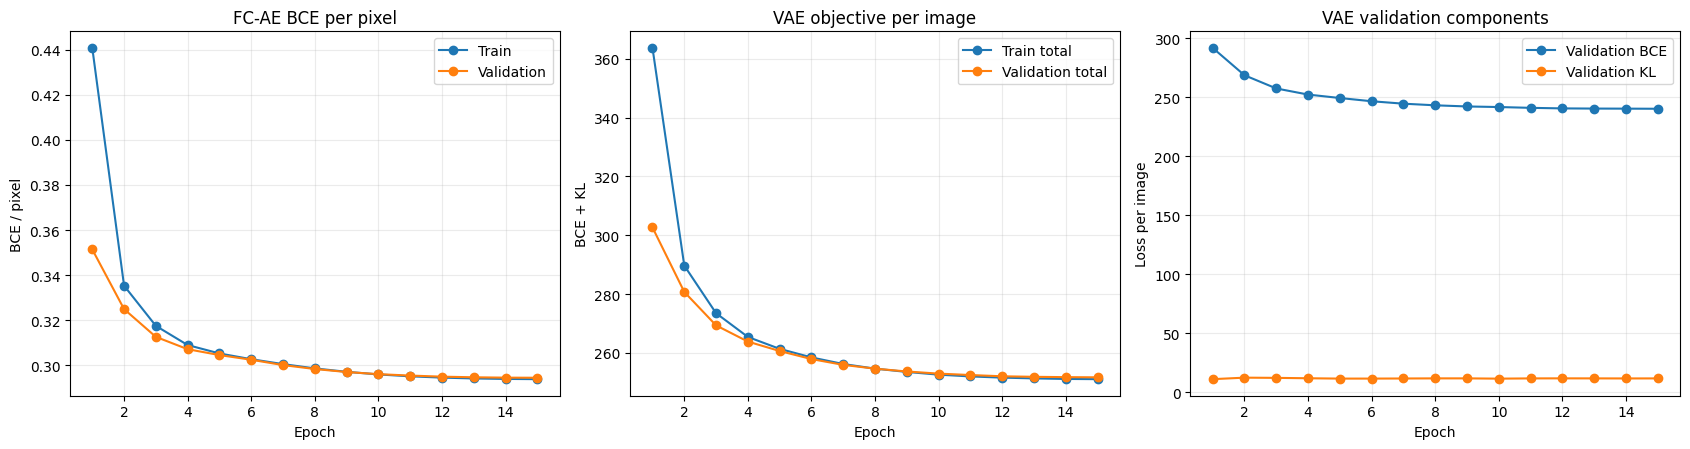

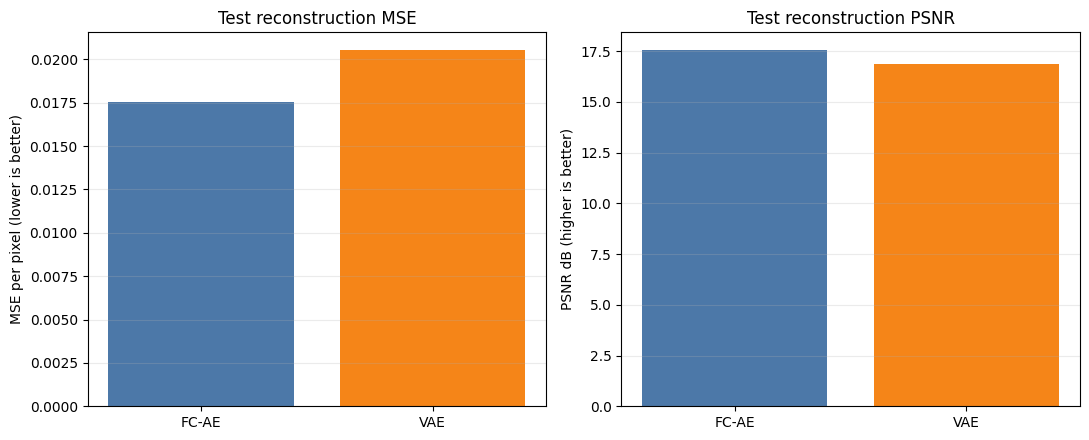

In [23]:
# Plot objective curves and common test metrics
history_df = pd.DataFrame(fc_history + vae_history)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

fc_rows = history_df[history_df["model"] == "FC-AE"]
axes[0].plot(fc_rows["epoch"], fc_rows["train_loss"], marker="o", label="Train")
axes[0].plot(fc_rows["epoch"], fc_rows["validation_loss"], marker="o", label="Validation")
axes[0].set_title("FC-AE BCE per pixel")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE / pixel")
axes[0].legend()
axes[0].grid(alpha=0.25)

vae_rows = history_df[history_df["model"] == "VAE"]
axes[1].plot(vae_rows["epoch"], vae_rows["train_loss"], marker="o", label="Train total")
axes[1].plot(vae_rows["epoch"], vae_rows["validation_loss"], marker="o", label="Validation total")
axes[1].set_title("VAE objective per image")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("BCE + KL")
axes[1].legend()
axes[1].grid(alpha=0.25)

axes[2].plot(vae_rows["epoch"], vae_rows["validation_reconstruction"], marker="o", label="Validation BCE")
axes[2].plot(vae_rows["epoch"], vae_rows["validation_kl"], marker="o", label="Validation KL")
axes[2].set_title("VAE validation components")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss per image")
axes[2].legend()
axes[2].grid(alpha=0.25)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "training_curves.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(metrics_df["model"], metrics_df["test_mse_per_pixel"], color=["#4C78A8", "#F58518"])
axes[0].set_title("Test reconstruction MSE")
axes[0].set_ylabel("MSE per pixel (lower is better)")
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(metrics_df["model"], metrics_df["test_psnr_db"], color=["#4C78A8", "#F58518"])
axes[1].set_title("Test reconstruction PSNR")
axes[1].set_ylabel("PSNR dB (higher is better)")
axes[1].grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_metric_comparison.png", dpi=180, bbox_inches="tight")
plt.show()


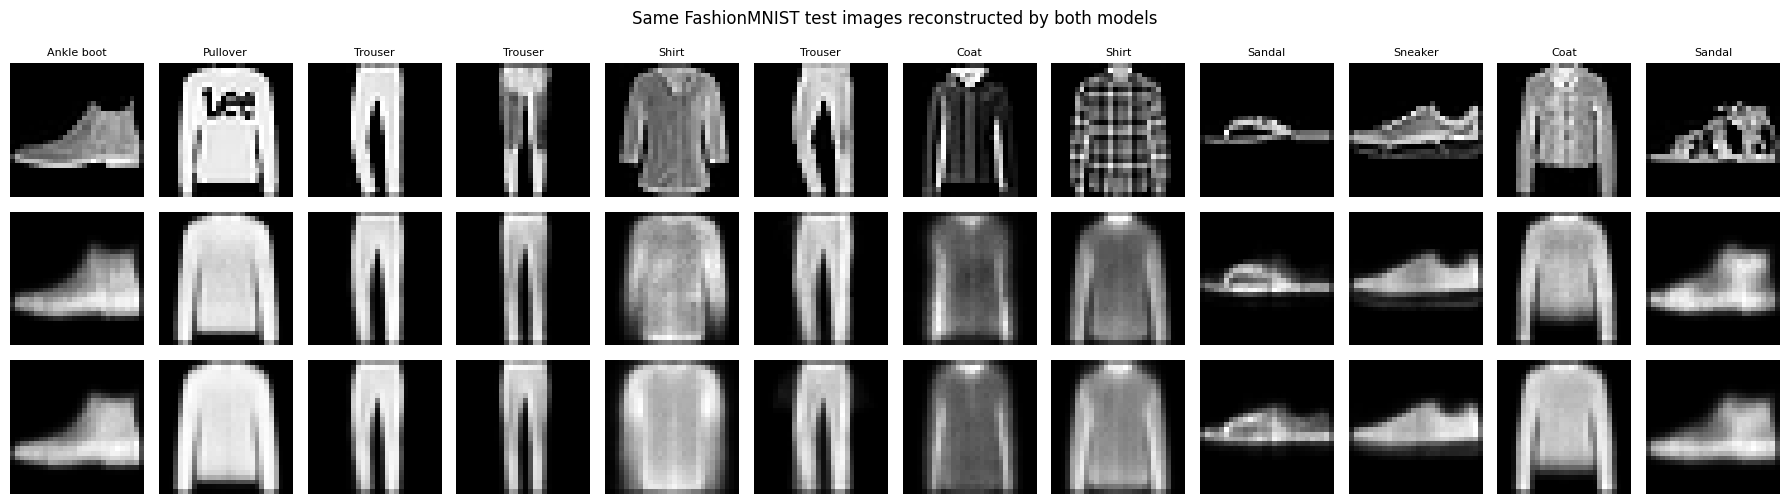

In [24]:
# Compare reconstructions on the exact same test images
comparison_images, comparison_labels = next(iter(test_loader))
comparison_images = comparison_images[:12].to(DEVICE)
comparison_labels = comparison_labels[:12]

fc_ae.eval()
vae.eval()
with torch.inference_mode():
    fc_reconstructions = fc_ae(comparison_images)
    vae_reconstructions, _, _ = vae.reconstruct_from_mean(comparison_images)

fig, axes = plt.subplots(3, 12, figsize=(18, 5.2))
for column in range(12):
    axes[0, column].imshow(comparison_images[column].cpu().reshape(28, 28), cmap="gray")
    axes[0, column].set_title(CLASS_NAMES[int(comparison_labels[column])], fontsize=8)
    axes[1, column].imshow(fc_reconstructions[column].cpu().reshape(28, 28), cmap="gray")
    axes[2, column].imshow(vae_reconstructions[column].cpu().reshape(28, 28), cmap="gray")
    for row in range(3):
        axes[row, column].axis("off")
axes[0, 0].set_ylabel("Original", fontsize=11)
axes[1, 0].set_ylabel("FC-AE", fontsize=11)
axes[2, 0].set_ylabel("VAE mean", fontsize=11)
fig.suptitle("Same FashionMNIST test images reconstructed by both models")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "reconstruction_comparison.png", dpi=180, bbox_inches="tight")
plt.show()


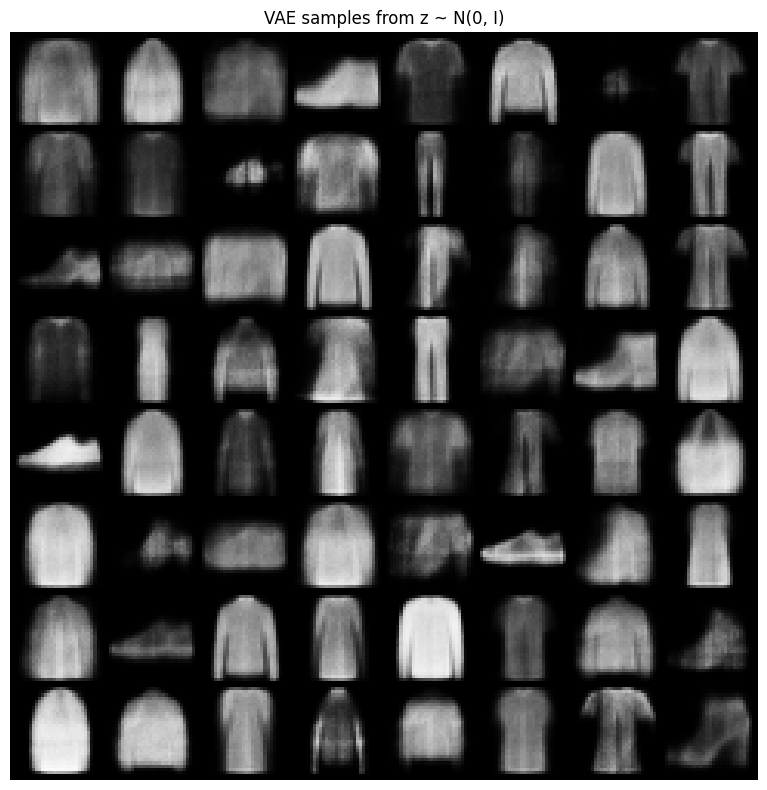

In [25]:
# Generate new FashionMNIST-like images by sampling the VAE prior
seed_everything(SEED + 1)
vae.eval()
with torch.inference_mode():
    random_latents = torch.randn(64, LATENT_DIM, device=DEVICE)
    generated_images = vae.decoder(random_latents).reshape(-1, 1, 28, 28).cpu()

grid = make_grid(generated_images, nrow=8, padding=2)
fig, axis = plt.subplots(figsize=(8, 8))
axis.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
axis.axis("off")
axis.set_title("VAE samples from z ~ N(0, I)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "vae_generated_samples.png", dpi=180, bbox_inches="tight")
plt.show()


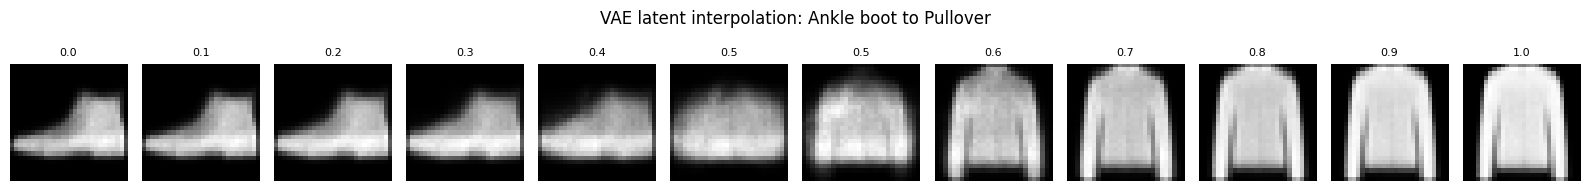

In [26]:
# VAE latent interpolation between two different test examples
image_a = comparison_images[0:1]
different_index = next(
    index for index, label in enumerate(comparison_labels)
    if int(label) != int(comparison_labels[0])
)
image_b = comparison_images[different_index:different_index + 1]

with torch.inference_mode():
    mu_a, _ = vae.encode(image_a)
    mu_b, _ = vae.encode(image_b)
    alphas = torch.linspace(0, 1, 12, device=DEVICE).unsqueeze(1)
    interpolated_latents = (1 - alphas) * mu_a + alphas * mu_b
    interpolations = vae.decoder(interpolated_latents).cpu()

fig, axes = plt.subplots(1, 12, figsize=(16, 2))
for index, axis in enumerate(axes):
    axis.imshow(interpolations[index].reshape(28, 28), cmap="gray")
    axis.axis("off")
    axis.set_title(f"{index/11:.1f}", fontsize=8)
fig.suptitle(
    f"VAE latent interpolation: {CLASS_NAMES[int(comparison_labels[0])]} to "
    f"{CLASS_NAMES[int(comparison_labels[different_index])]}"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "vae_latent_interpolation.png", dpi=180, bbox_inches="tight")
plt.show()


## Interpretation guide

The next cell generates the final interpretation from the measured test results rather than inserting assumed numbers. A typical result is that the deterministic FC-AE achieves lower reconstruction error, while the VAE produces a smoother latent space from which meaningful new samples can be drawn. The exact conclusion should follow this run's displayed metrics and images.


In [27]:
fc_mse = float(metrics_df.loc[metrics_df["model"] == "FC-AE", "test_mse_per_pixel"].iloc[0])
vae_mse = float(metrics_df.loc[metrics_df["model"] == "VAE", "test_mse_per_pixel"].iloc[0])
fc_psnr = float(metrics_df.loc[metrics_df["model"] == "FC-AE", "test_psnr_db"].iloc[0])
vae_psnr = float(metrics_df.loc[metrics_df["model"] == "VAE", "test_psnr_db"].iloc[0])

reconstruction_winner = "FC-AE" if fc_mse < vae_mse else "VAE"
relative_gap = abs(fc_mse - vae_mse) / min(fc_mse, vae_mse) * 100

interpretation_lines = [
    f"The {reconstruction_winner} produced the lower test MSE in this run. "
    f"FC-AE MSE was {fc_mse:.6f}, while VAE MSE was {vae_mse:.6f}; "
    f"the difference relative to the lower value was {relative_gap:.2f}%.",
    f"FC-AE achieved {fc_psnr:.2f} dB PSNR and the VAE achieved {vae_psnr:.2f} dB. "
    "These common metrics compare reconstruction quality on the same test images.",
    "The FC-AE maps each input to one deterministic latent code and is optimized only for reconstruction. "
    "This usually allows sharper reconstruction but does not force unused regions of latent space to decode meaningfully.",
    "The VAE regularizes each posterior toward a standard-normal prior. The KL term makes its latent space smoother "
    "and supports random generation and interpolation, but that constraint can blur details and increase reconstruction error.",
    "The reconstruction grid should be used to judge retained garment shape and fine details, while the random-sample "
    "grid and interpolation demonstrate the VAE's generative behavior."
]

for line in interpretation_lines:
    print("-", line)
    log("Interpretation: " + line)


- The FC-AE produced the lower test MSE in this run. FC-AE MSE was 0.017556, while VAE MSE was 0.020528; the difference relative to the lower value was 16.92%.
[2026-10-20T06:56:37.521261+00:00] Interpretation: The FC-AE produced the lower test MSE in this run. FC-AE MSE was 0.017556, while VAE MSE was 0.020528; the difference relative to the lower value was 16.92%.
- FC-AE achieved 17.56 dB PSNR and the VAE achieved 16.88 dB. These common metrics compare reconstruction quality on the same test images.
[2026-10-20T06:56:37.521305+00:00] Interpretation: FC-AE achieved 17.56 dB PSNR and the VAE achieved 16.88 dB. These common metrics compare reconstruction quality on the same test images.
- The FC-AE maps each input to one deterministic latent code and is optimized only for reconstruction. This usually allows sharper reconstruction but does not force unused regions of latent space to decode meaningfully.
[2026-10-20T06:56:37.521325+00:00] Interpretation: The FC-AE maps each input to one 

# Export submission artifacts

This cell saves measured metrics, histories, figures, model weights, documentation, and reproducibility metadata. It then creates a ZIP for convenient download. The executed notebook must still be downloaded separately from Colab and added to the final GitHub folder.


In [28]:
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
metrics_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
class_metrics_df.to_csv(OUTPUT_DIR / "per_class_metrics.csv", index=False)

run_config = {
    "student": STUDENT,
    "SID4": SID4,
    "SEED": SEED,
    "SLICE": SLICE,
    "HP_ID": HP_ID,
    "CLS_A": CLS_A,
    "CLS_B": CLS_B,
    "dataset": "FashionMNIST",
    "models": ["Fully Connected Autoencoder", "Variational Autoencoder"],
    "latent_dim": LATENT_DIM,
    "batch_size": BATCH_SIZE,
    "epochs_fc_ae": EPOCHS_FC,
    "epochs_vae": EPOCHS_VAE,
    "learning_rate": LEARNING_RATE,
    "vae_beta": BETA,
    "train_size": len(train_dataset),
    "validation_size": len(validation_dataset),
    "test_size": len(test_dataset),
    "fast_dev_run": FAST_DEV_RUN,
}
(OUTPUT_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")

environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "device": str(DEVICE),
    "hardware": gpu_name,
}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")

metrics_table = metrics_df.copy()
for column in ["test_mse_per_pixel", "test_mae_per_pixel", "test_bce_per_pixel"]:
    metrics_table[column] = metrics_table[column].map(lambda value: f"{value:.6f}")
metrics_table["test_psnr_db"] = metrics_table["test_psnr_db"].map(lambda value: f"{value:.3f}")
metrics_table["test_kl_per_image"] = metrics_table["test_kl_per_image"].map(
    lambda value: "N/A" if pd.isna(value) else f"{value:.6f}"
)

metrics_md = f"""# Homework 7 Metrics

Student: {STUDENT}
SID4: {SID4}
Dataset: FashionMNIST
Seed: {SEED}

## Test-set comparison

{metrics_table.to_markdown(index=False)}

## Interpretation

{chr(10).join('- ' + line for line in interpretation_lines)}

## Experimental controls

- Both models were trained on the same {len(train_dataset):,} training examples.
- Both used the same {len(validation_dataset):,} validation and {len(test_dataset):,} test examples.
- Both used latent dimension {LATENT_DIM}, batch size {BATCH_SIZE}, and seed {SEED}.
- Final evaluation used deterministic reconstructions on the identical test set.
- VAE generation sampled latent vectors from the standard-normal prior.
"""
(OUTPUT_DIR / "METRICS.md").write_text(metrics_md, encoding="utf-8")

analysis_md = f"""# Homework 7 Analysis

## GAN theory

The complete responses to Questions 1A-1C are included in the executed notebook. They cover the GAN minimax game, mode collapse with three mitigation mechanisms, and DCGAN, Conditional GAN, and CycleGAN.

## Autoencoder comparison

{chr(10).join(interpretation_lines)}

The FC-AE is preferable when the main goal is deterministic compression and accurate reconstruction. The VAE is preferable when a structured, sampleable latent space and controlled interpolation are important. Their objectives differ, so the common test MSE, MAE, BCE, and PSNR values are used for the direct reconstruction comparison.
"""
(OUTPUT_DIR / "ANALYSIS.md").write_text(analysis_md, encoding="utf-8")

ai_use_md = """# AI Use - Homework 7

I used an AI assistant to develop a first-cut notebook structure, translate the assignment requirements into an executable experiment, and debug the training and evaluation workflow. It helped me understand the GAN minimax objective, mode collapse, the distinction between deterministic and variational autoencoders, and how to compare the models with common metrics. I ran the notebook, reviewed the outputs and generated images, checked the saved metrics against the displayed results, and revised the final explanations so I could describe the methods and conclusions in my own words.
"""
(OUTPUT_DIR / "AI_USE.md").write_text(ai_use_md, encoding="utf-8")

readme_md = f"""# DATA 266 Homework 7 - GAN Theory and FashionMNIST Autoencoders

Student: {STUDENT}
SID4: {SID4}

This submission answers the GAN theory questions and trains/evaluates a fully connected autoencoder and a variational autoencoder on FashionMNIST in PyTorch.

## Main files

- `HW7_FashionMNIST_AE_VAE_Nikhil_Kanaparthi_6441.ipynb`: executed notebook with theory, code, outputs, and interpretations; add after downloading from Colab.
- `METRICS.md`: measured test results and comparison.
- `ANALYSIS.md`: final conclusions.
- `AI_USE.md`: AI-use disclosure.
- `RUN_LOG.txt`: timestamped execution record.
- `metrics.csv`, `per_class_metrics.csv`, and `training_history.csv`: raw measurements.
- `figures/`: dataset examples, curves, reconstructions, VAE samples, and interpolation.
- `models/`: PyTorch state dictionaries.
- `run_config.json` and `environment.json`: reproducibility information.

## Final measured result

The lower test reconstruction MSE was produced by **{reconstruction_winner}** in this run.

## Submission

Commit the extracted folder and executed notebook to `data266-6441/HW7`, create tag `hw7` after the final commit, and submit the tagged HW7 folder URL.
"""
(OUTPUT_DIR / "README.md").write_text(readme_md, encoding="utf-8")

RUN_LOG_LINES.append("TRAINING HISTORY")
for record in history_df.to_dict(orient="records"):
    RUN_LOG_LINES.append(json.dumps(record, sort_keys=True, default=str, allow_nan=True))
(OUTPUT_DIR / "RUN_LOG.txt").write_text("\n".join(RUN_LOG_LINES) + "\n", encoding="utf-8")

manifest_lines = []
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        manifest_lines.append(f"{path.relative_to(OUTPUT_DIR)}\t{path.stat().st_size} bytes")
(OUTPUT_DIR / "submission_manifest.txt").write_text("\n".join(manifest_lines) + "\n", encoding="utf-8")

archive_base = Path("/content/HW7_FashionMNIST_Nikhil_Kanaparthi_6441_runtime_artifacts")
archive_path = Path(shutil.make_archive(str(archive_base), "zip", OUTPUT_DIR.parent, OUTPUT_DIR.name))

print("Created submission artifacts:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(" -", path.relative_to(OUTPUT_DIR))
print("ZIP:", archive_path)

try:
    from google.colab import files
    files.download(str(archive_path))
except ImportError:
    print("Not running in Colab. Download the ZIP manually from:", archive_path)


Created submission artifacts:
 - AI_USE.md
 - ANALYSIS.md
 - METRICS.md
 - README.md
 - RUN_LOG.txt
 - environment.json
 - figures/fashionmnist_examples.png
 - figures/reconstruction_comparison.png
 - figures/test_metric_comparison.png
 - figures/training_curves.png
 - figures/vae_generated_samples.png
 - figures/vae_latent_interpolation.png
 - metrics.csv
 - models/fc_autoencoder_state_dict.pt
 - models/variational_autoencoder_state_dict.pt
 - per_class_metrics.csv
 - run_config.json
 - submission_manifest.txt
 - training_history.csv
ZIP: /content/HW7_FashionMNIST_Nikhil_Kanaparthi_6441_runtime_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Final submission checklist

1. Confirm `FAST_DEV_RUN` was **False** for the final run.
2. Confirm every code cell completed without an exception.
3. Download the runtime-artifacts ZIP generated above.
4. In Colab, choose **File > Download > Download .ipynb**.
5. Rename the notebook exactly `HW7_FashionMNIST_AE_VAE_Nikhil_Kanaparthi_6441.ipynb`.
6. Extract the ZIP and place the executed notebook inside the extracted folder.
7. Upload the complete folder to `data266-6441/HW7` using sequential commits.
8. Create tag `hw7` only after the final commit.
9. Submit the tagged folder URL in Canvas.

Suggested commits:

1. `HW7: add GAN theory and experiment setup`
2. `HW7: implement and train FashionMNIST FC-AE`
3. `HW7: implement and train FashionMNIST VAE`
4. `HW7: add evaluation figures and measured metrics`
5. `HW7: add final analysis documentation and AI disclosure`

The assignment requests a website URL and does not explicitly request a separate report PDF. The executed notebook contains the written responses and experimental report.
